In [11]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

df = pd.read_csv('../01 - DataPreparation/df_prepared.csv')

print(df.columns)


Index(['BGGId', 'GameWeight', 'MinPlayers', 'MaxPlayers', 'NumOwned',
       'NumWant', 'NumAlternates', 'NumExpansions', 'NumImplementations',
       'IsReimplementation', 'Kickstarted', 'Cat:Thematic', 'Cat:Strategy',
       'Cat:War', 'Cat:Family', 'Cat:CGS', 'Cat:Abstract', 'Cat:Party',
       'Cat:Childrens', 'Rating', 'Age', 'AvgPlaytime', 'AgeRec',
       'NumOwned_log', 'NumAlternates_log', 'NumExpansions_log',
       'NumImplementations_log', 'NumWant_log', 'AvgPlaytime_log',
       'MaxPlayers_log'],
      dtype='object')


The initial feature selection includes all of them because Decision Trees are extremely strong against unnecessary data.

In [12]:
feature_columns = ['GameWeight', 'MinPlayers', 'MaxPlayers', 'NumOwned',
       'NumWant', 'NumAlternates', 'NumExpansions', 'NumImplementations',
       'IsReimplementation', 'Kickstarted', 'Cat:Thematic', 'Cat:Strategy',
       'Cat:War', 'Cat:Family', 'Cat:CGS', 'Cat:Abstract', 'Cat:Party',
       'Cat:Childrens', 'Age', 'AvgPlaytime', 'AgeRec',
       'NumOwned_log', 'NumAlternates_log', 'NumExpansions_log',
       'NumImplementations_log', 'NumWant_log', 'AvgPlaytime_log',
       'MaxPlayers_log']

X = df[feature_columns]
y = df['Rating']

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)


In [14]:
dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

y_pred = dt.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred),2))

print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.62

Confusion Matrix:
 [[ 916   70  448]
 [  72 1234  678]
 [ 470  609 1675]]

Classification Report:
               precision    recall  f1-score   support

        High       0.63      0.64      0.63      1434
         Low       0.65      0.62      0.63      1984
      Medium       0.60      0.61      0.60      2754

    accuracy                           0.62      6172
   macro avg       0.62      0.62      0.62      6172
weighted avg       0.62      0.62      0.62      6172



Base (untuned) decision tree achieves 0.62 accuracy with balanced performance across classes (precision/recall/F1 ≈ 0.61–0.64). The main errors are confusions between Medium and the other classes, while High vs Low is less frequently mixed up.

We now run a 5-fold GridSearchCV to tune a DecisionTreeClassifier over multiple hyperparameters optimizing for macro F1

In [15]:
param_grid = {
    'criterion': ['gini', 'entropy','log_loss'],
    'splitter': ['random','best'],
    'max_depth': [None, 3, 5, 7, 8, 9, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5, 10],
    'min_impurity_decrease' : [0.0, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3],
    'class_weight': [
        None,
        'balanced',
        {'Low':1, 'Medium':1.5, 'High':1},
        {'Low':1, 'Medium':2, 'High':1},
        {'Low':1, 'Medium':1.2, 'High':1}
    ]
}

dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'class_weight': [None, 'balanced', ...], 'criterion': ['gini', 'entropy', ...], 'max_depth': [None, 3, ...], 'min_impurity_decrease': [0.0, 1e-07, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the com

In [21]:
print("Best Parameters:", dt_grid.best_params_)
print("Best CV F1 Score:", dt_grid.best_score_)

Best Parameters: {'class_weight': None, 'criterion': 'entropy', 'max_depth': 9, 'min_impurity_decrease': 0.0001, 'min_samples_leaf': 10, 'min_samples_split': 2, 'splitter': 'random'}
Best CV F1 Score: 0.6779164110849722


Grid search finds a deeper but regularized tree (depth=8, leaf>=10, small impurity decrease) and improves macro-F1 to ~0.684 in 5-fold CV (better balanced performance across classes vs. the untuned baseline).

In [22]:
best_dt = dt_grid.best_estimator_

y_pred_train = best_dt.predict(X_train)
y_pred_test = best_dt.predict(X_test)

train_acc = accuracy_score(y_train, y_pred_train)
test_acc = accuracy_score(y_test, y_pred_test)

print(f"Train accuracy: {train_acc:.3f}")
print(f"Test accuracy: {test_acc:.3f}\n")



# Confusion matrix
print("Confusion Matrix (Test Set):")
print(confusion_matrix(y_test, y_pred_test))

# Classification report
print("\nClassification Report (Test Set):")
print(classification_report(y_test, y_pred_test))

Train accuracy: 0.699
Test accuracy: 0.678

Confusion Matrix (Test Set):
[[ 890   40  504]
 [  25 1401  558]
 [ 282  577 1895]]

Classification Report (Test Set):
              precision    recall  f1-score   support

        High       0.74      0.62      0.68      1434
         Low       0.69      0.71      0.70      1984
      Medium       0.64      0.69      0.66      2754

    accuracy                           0.68      6172
   macro avg       0.69      0.67      0.68      6172
weighted avg       0.68      0.68      0.68      6172



Tuned decision tree generalizes better than the baseline (test acc 0.678; macro-F1 ~0.69). Biggest remaining confusion is High ↔ Medium, while Low is the most reliably predicted class.


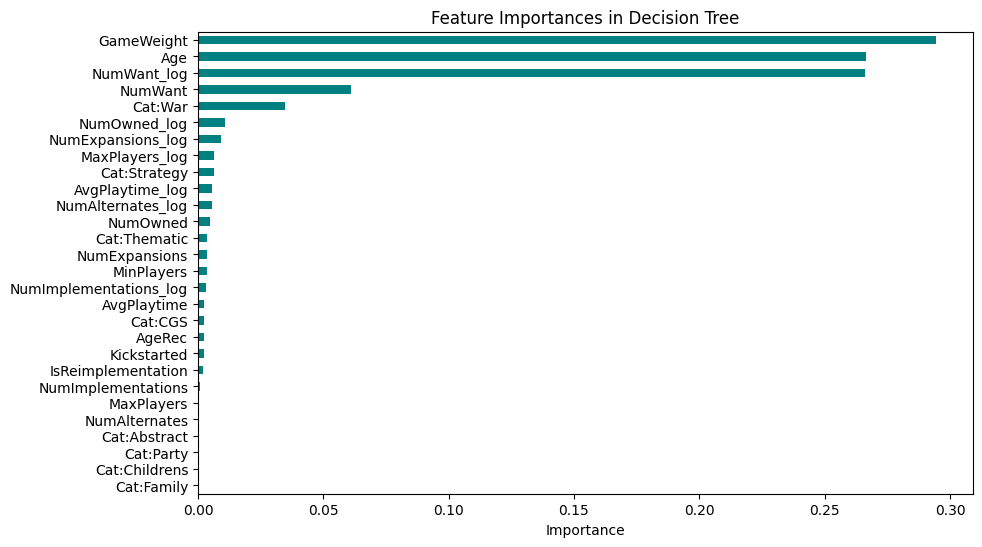

In [18]:
import matplotlib.pyplot as plt

importances = pd.Series(best_dt.feature_importances_, index=feature_columns).sort_values(ascending=True)

plt.figure(figsize=(10,6))
importances.plot(kind='barh', color='teal')
plt.title("Feature Importances in Decision Tree")
plt.xlabel("Importance")
plt.show()


We now plot Feature importances in the Decision Tree showing that the most important features are GameWeight, Age, NumWant_log and Cat:war.

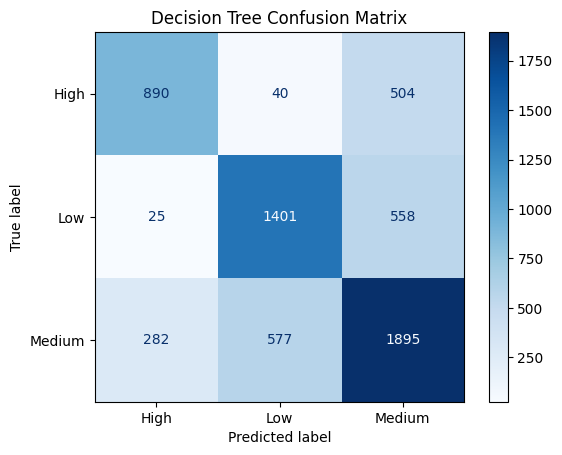

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_test, labels=best_dt.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_dt.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title("Decision Tree Confusion Matrix")
plt.show()


From the confusion matrix we can confirm that most predictions fall on the diagonal, but High and Low are frequently misclassified as Medium, and Medium is sometimes predicted as Low; High - Low confusion is minimal.

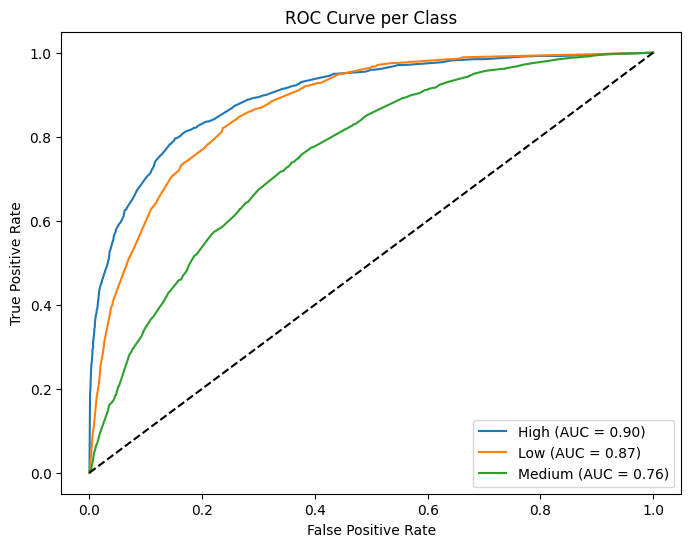

In [20]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

y_bin = label_binarize(y_test, classes=best_dt.classes_)
y_score = best_dt.predict_proba(X_test)

plt.figure(figsize=(8,6))
for i, class_label in enumerate(best_dt.classes_):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_score[:, i])
    plt.plot(fpr, tpr, label=f'{class_label} (AUC = {auc(fpr, tpr):.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve per Class")
plt.legend()
plt.show()


ROC curves show strong class separability for High (AUC=0.90) and Low (AUC=0.87), but weaker discrimination for Medium (AUC=0.76);
all curves sit well above the diagonal baseline, indicating better-than-random performance.
